# Quantum Simulation of Superposition and Entanglement: A NumPy–Qiskit Study

## Project Overview

This project investigates the preparation and measurement of a two-qubit Bell state using NumPy and Qiskit.

**Objectives**

* Construct a Bell state using matrix operations in NumPy.
* Prepare the corresponding quantum circuit using Qiskit.
* Compare theoretical probabilities with simulated measurement frequencies.
* Examine the entanglement of the resulting pure two-qubit state.

**Tools:** Python, NumPy, Qiskit, Qiskit Aer and Matplotlib.

**Scope:** Educational simulation using an ideal quantum circuit simulator; no physical quantum hardware experiment is claimed.

In [24]:
%pip install -q numpy matplotlib qiskit qiskit-aer

In [25]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

print("All libraries imported successfully!")

All libraries imported successfully!


**NUMPY** **SIMULATION**

In [26]:
# Identity matrix
I = np.eye(2)

# Hadamard gate
H = np.array([
    [1, 1],
    [1, -1]
]) / np.sqrt(2)

# CNOT: first qubit controls the second
CNOT = np.array([
    [1, 0, 0, 0],
    [0, 1, 0, 0],
    [0, 0, 0, 1],
    [0, 0, 1, 0]
])

# Initial state |00>
zero_zero = np.array([1, 0, 0, 0])

# Apply H to the first qubit, then CNOT
after_h = np.kron(H, I) @ zero_zero
bell_numpy = CNOT @ after_h

# Theoretical probabilities
prob_numpy = np.abs(bell_numpy) ** 2

print("NumPy Bell state:")
print(bell_numpy)

print("\nNumPy probabilities:")
print(prob_numpy)

NumPy Bell state:
[0.70710678 0.         0.         0.70710678]

NumPy probabilities:
[0.5 0.  0.  0.5]


**QISKIT CIRCUIT**

In [27]:
qc = QuantumCircuit(2)

qc.h(0)
qc.cx(0, 1)

print(qc.draw())

     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘


In [28]:
qiskit_state = Statevector.from_instruction(qc)

bell_qiskit = qiskit_state.data
prob_qiskit = qiskit_state.probabilities()

print("Qiskit statevector:")
print(bell_qiskit)

print("\nQiskit probabilities:")
print(prob_qiskit)

print(
    "\nProbabilities match:",
    np.allclose(prob_numpy, prob_qiskit)
)

Qiskit statevector:
[0.70710678+0.j 0.        +0.j 0.        +0.j 0.70710678+0.j]

Qiskit probabilities:
[0.5 0.  0.  0.5]

Probabilities match: True


**MEASUREMENT EXPERIMENT**

In [29]:
measured_qc = QuantumCircuit(2, 2)
measured_qc.h(0)
measured_qc.cx(0, 1)
measured_qc.measure([0, 1], [0, 1])

simulator = AerSimulator()

result = simulator.run(
    measured_qc,
    shots=5000,
    seed_simulator=42
).result()

counts = result.get_counts()

outcomes = ["00", "01", "10", "11"]
values = [counts.get(x, 0) for x in outcomes]

print("Measurement counts:", counts)

for outcome, count in zip(outcomes, values):
    print(f"{outcome}: {count / 5000:.3f}")

Measurement counts: {'11': 2571, '00': 2429}
00: 0.486
01: 0.000
10: 0.000
11: 0.514


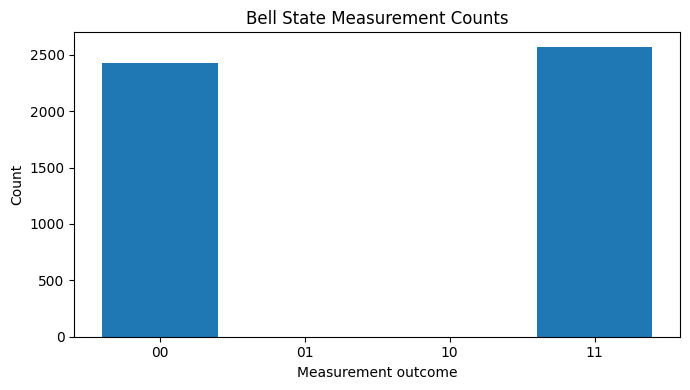

In [30]:
plt.figure(figsize=(7, 4))
plt.bar(outcomes, values)
plt.xlabel("Measurement outcome")
plt.ylabel("Count")
plt.title("Bell State Measurement Counts")
plt.tight_layout()
plt.show()

**ENTANGLEMENT VERIFICATION**

In [31]:
coefficient_matrix = bell_numpy.reshape(2, 2)
determinant = np.linalg.det(coefficient_matrix)

print("Coefficient matrix:")
print(coefficient_matrix)

print("\nDeterminant:", determinant)
print("Entangled:", not np.isclose(determinant, 0))

Coefficient matrix:
[[0.70710678 0.        ]
 [0.         0.70710678]]

Determinant: 0.4999999999999999
Entangled: True


## Results and Discussion

The Bell state was constructed using two approaches: matrix operations in NumPy and a quantum circuit in Qiskit.

The circuit applied a Hadamard gate to the first qubit, followed by a CNOT gate with the first qubit as control and the second as target.

The resulting state was

$$
|\Phi^+\rangle=\frac{|00\rangle+|11\rangle}{\sqrt{2}}.
$$

The theoretical measurement probabilities were 0.5 for outcomes 00 and 11, and 0 for outcomes 01 and 10.

The NumPy and Qiskit probability calculations agreed. The simulated measurement outcomes were consistent with the theoretical predictions for an ideal circuit.

The coefficient-matrix determinant test also indicated that the resulting pure two-qubit state is entangled.

## Conclusion

This project demonstrated the construction and simulation of a Bell state using NumPy and Qiskit. It connected matrix operations, quantum gates, statevectors, measurement probabilities, and a mathematical test for pure-state entanglement.

The experiment provides a foundation for further study of quantum circuits and quantum information.

## Limitations

This study used an ideal simulator rather than physical quantum hardware. It therefore does not model real-device noise, gate errors, or measurement errors. The determinant test used here applies to pure two-qubit states and is not a general entanglement test for mixed states.